# Tugas 1 - Perbandingan Kernel SVM pada Data Suara

In [1]:
# Langkah 1 - Import Library dan Load Data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

data = pd.read_csv('data/voice.csv')
display(data.head())
print('Ukuran data:', data.shape)
print('Jumlah nilai kosong:', data.isna().sum().sum())
print('Jumlah duplikat:', data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)
print('Ukuran data setelah dibersihkan:', data.shape)
print(data['label'].value_counts())

Ukuran data: (3168, 21)
Jumlah nilai kosong: 0
Jumlah duplikat: 2
Ukuran data setelah dibersihkan: (3166, 21)
label
male      1583
female    1583
Name: count, dtype: int64


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,0.000000,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,0.000000,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,0.000000,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,0.083878,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,0.104261,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [2]:
# Langkah 2 - Pisahkan Fitur dan Label
X = data.drop(columns='label')
y = data['label']
print('Jumlah fitur:', X.shape[1])

Jumlah fitur: 20


In [3]:
# Langkah 3 - Percobaan Split 70:30 dan 80:20 untuk Setiap Kernel
hasil_svm = []
for rasio, test_size in [('70:30', 0.3), ('80:20', 0.2)]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )
    for kernel in ['linear', 'poly', 'rbf']:
        # Scaler hanya mempelajari data latih, kemudian digunakan pada data uji.
        model = Pipeline([
            ('scaler', StandardScaler()),
            ('svm', SVC(kernel=kernel, C=1.0, gamma='scale', degree=3))
        ])
        model.fit(X_train, y_train)
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)
        hasil_svm.append({
            'Split': rasio,
            'Kernel': {'linear': 'Linear', 'poly': 'Polynomial', 'rbf': 'RBF'}[kernel],
            'Jumlah Train': len(X_train), 'Jumlah Test': len(X_test),
            'Akurasi Train': accuracy_score(y_train, y_train_pred),
            'Akurasi Test': accuracy_score(y_test, y_test_pred)
        })

tabel_svm = pd.DataFrame(hasil_svm)
display(tabel_svm)

,Split,Kernel,Jumlah Train,Jumlah Test,Akurasi Train,Akurasi Test
0,70:30,Linear,2216,950,0.976083,0.973684
1,70:30,Polynomial,2216,950,0.966155,0.957895
2,70:30,RBF,2216,950,0.985560,0.981053
3,80:20,Linear,2532,634,0.975908,0.973186
4,80:20,Polynomial,2532,634,0.966825,0.962145
5,80:20,RBF,2532,634,0.984992,0.982650


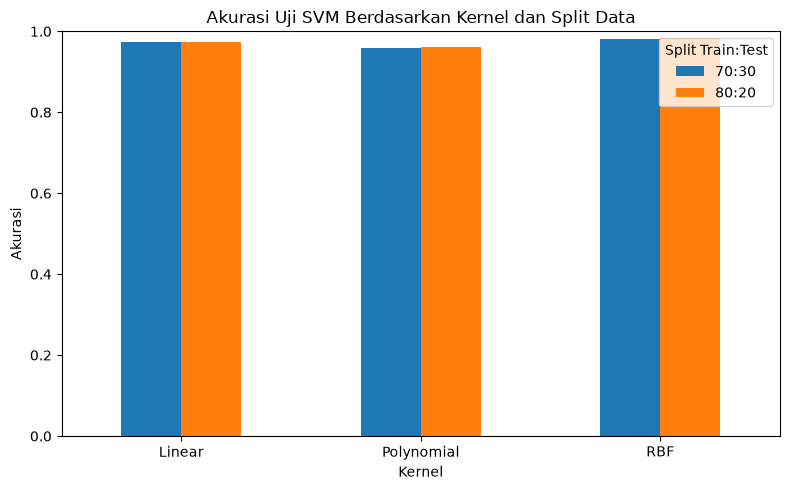

In [4]:
# Langkah 4 - Visualisasi Perbandingan Akurasi
tabel_svm.pivot(index='Kernel', columns='Split', values='Akurasi Test').plot(
    kind='bar', figsize=(8, 5), rot=0
)
plt.title('Akurasi Uji SVM Berdasarkan Kernel dan Split Data')
plt.xlabel('Kernel')
plt.ylabel('Akurasi')
plt.ylim(0, 1)
plt.legend(title='Split Train:Test')
plt.tight_layout()
plt.show()

# Tugas 2 - Klasifikasi Siang dan Malam dengan Histogram dan SVM RBF

In [5]:
# Langkah 1 - Load Daftar Gambar dari Data Praktikum 5
from pathlib import Path
import hashlib
import matplotlib.image as mpimg
import cv2

# Gabungkan kedua folder, lalu buat pembagian baru 80:20 sesuai tugas.
image_dirs = [Path('data/images/training'), Path('data/images/test')]
daftar_gambar = []
for img_dir in image_dirs:
    for folder in sorted(img_dir.iterdir()):
        if not folder.is_dir():
            continue
        for file in sorted(folder.glob('*.jpg')):
            daftar_gambar.append({
                'Path': str(file), 'Label': folder.name,
                'Hash': hashlib.sha256(file.read_bytes()).hexdigest()
            })

data_gambar = pd.DataFrame(daftar_gambar)
print('Jumlah gambar awal:', len(data_gambar))
print('Jumlah gambar duplikat:', data_gambar.duplicated('Hash').sum())
data_gambar = data_gambar.drop_duplicates('Hash').reset_index(drop=True)
print('Jumlah gambar setelah dibersihkan:', len(data_gambar))
print(data_gambar['Label'].value_counts())

Jumlah gambar awal: 400
Jumlah gambar duplikat: 1
Jumlah gambar setelah dibersihkan: 399
Label
night    200
day      199
Name: count, dtype: int64


In [6]:
# Langkah 2 - Standarisasi Gambar dan Ekstraksi Fitur Histogram
def standarized_input(image):
    return cv2.resize(image, (1100, 600))

def extract_histogram(image):
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    fitur = []
    # Masing-masing kanal H, S, dan V menggunakan 32 bin.
    for channel, batas in [(0, 180), (1, 256), (2, 256)]:
        hist = cv2.calcHist([img_hsv], [channel], None, [32], [0, batas])
        hist = hist.ravel()
        hist = hist / hist.sum()
        fitur.extend(hist)
    return np.asarray(fitur, dtype=np.float32)

fitur_gambar = []
for file in data_gambar['Path']:
    image = mpimg.imread(file)
    image = standarized_input(image)
    fitur_gambar.append(extract_histogram(image))

X_gambar = np.asarray(fitur_gambar)
# Encoding sesuai Praktikum 5: day = 1 dan night = 0.
y_gambar = data_gambar['Label'].map({'day': 1, 'night': 0}).to_numpy()
print('Ukuran fitur histogram:', X_gambar.shape)

Ukuran fitur histogram: (399, 96)


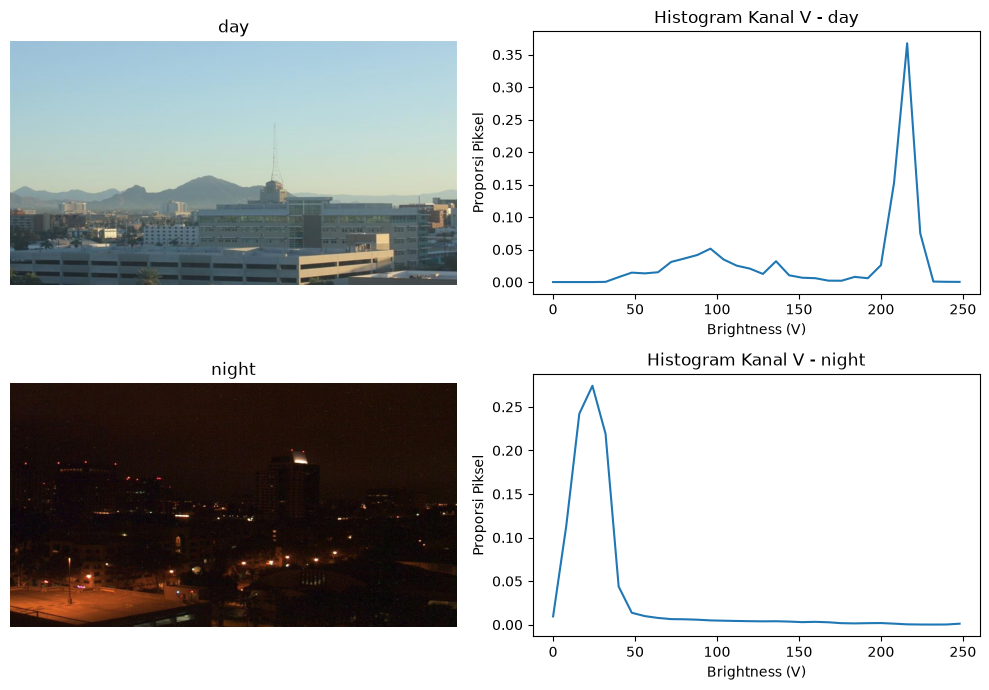

In [7]:
# Langkah 3 - Visualisasi Contoh Gambar dan Histogram Brightness
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for i, label in enumerate(['day', 'night']):
    file = data_gambar.loc[data_gambar['Label'] == label, 'Path'].iloc[0]
    image = standarized_input(mpimg.imread(file))
    fitur = extract_histogram(image)
    axes[i, 0].imshow(image)
    axes[i, 0].set_title(label)
    axes[i, 0].axis('off')
    axes[i, 1].plot(np.linspace(0, 256, 32, endpoint=False), fitur[64:])
    axes[i, 1].set_title(f'Histogram Kanal V - {label}')
    axes[i, 1].set_xlabel('Brightness (V)')
    axes[i, 1].set_ylabel('Proporsi Piksel')
plt.tight_layout()
plt.show()

In [8]:
# Langkah 4 - Split Data Gambar 80:20
X_train_img, X_test_img, y_train_img, y_test_img = train_test_split(
    X_gambar, y_gambar, test_size=0.2, random_state=42, stratify=y_gambar
)
print('Jumlah data latih:', len(X_train_img))
print('Jumlah data uji:', len(X_test_img))

Jumlah data latih: 319
Jumlah data uji: 80


In [9]:
# Langkah 5 - Training dan Hyperparameter Tuning SVM RBF
model_gambar = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf'))
])
parameter = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 0.001, 0.01, 0.1, 1]
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pencarian = GridSearchCV(model_gambar, parameter, cv=cv, scoring='accuracy', n_jobs=1)
pencarian.fit(X_train_img, y_train_img)
print('Parameter terbaik:', pencarian.best_params_)
print('Rata-rata akurasi validasi:', pencarian.best_score_)

hasil_tuning = pd.DataFrame(pencarian.cv_results_)
display(hasil_tuning[['param_svm__C', 'param_svm__gamma', 'mean_test_score']]
        .sort_values('mean_test_score', ascending=False).reset_index(drop=True))

Parameter terbaik: {'svm__C': 1, 'svm__gamma': 'scale'}
Rata-rata akurasi validasi: 0.9905257936507936


,param_svm__C,param_svm__gamma,mean_test_score
0,10.0,0.001,0.990526
1,10.0,scale,0.990526
2,1.0,0.01,0.990526
3,1.0,scale,0.990526
4,100.0,0.001,0.990526
5,100.0,0.01,0.990526
6,100.0,scale,0.990526
7,10.0,0.01,0.990526
8,1.0,0.001,0.987450
9,0.1,scale,0.968651


              precision    recall  f1-score   support

       night     0.9756    1.0000    0.9877        40
         day     1.0000    0.9750    0.9873        40

    accuracy                         0.9875        80
   macro avg     0.9878    0.9875    0.9875        80
weighted avg     0.9878    0.9875    0.9875        80



,Split,Kernel,Fitur,C,Gamma,Akurasi Validasi,Akurasi Train,Akurasi Test
0,80:20,RBF,Histogram HSV (96 fitur),1,scale,0.990526,1.0,0.9875


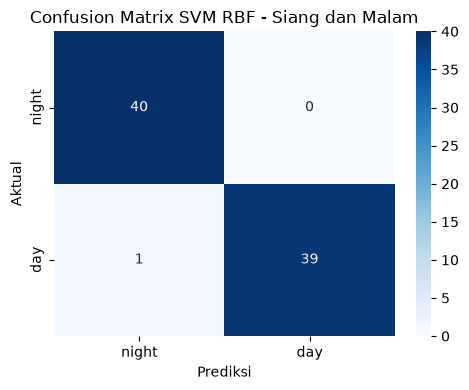

In [10]:
# Langkah 6 - Evaluasi Model Gambar pada Data Uji
model_terbaik = pencarian.best_estimator_
y_train_pred_img = model_terbaik.predict(X_train_img)
y_test_pred_img = model_terbaik.predict(X_test_img)
acc_train_img = accuracy_score(y_train_img, y_train_pred_img)
acc_test_img = accuracy_score(y_test_img, y_test_pred_img)

tabel_gambar = pd.DataFrame([{
    'Split': '80:20', 'Kernel': 'RBF', 'Fitur': 'Histogram HSV (96 fitur)',
    'C': pencarian.best_params_['svm__C'],
    'Gamma': pencarian.best_params_['svm__gamma'],
    'Akurasi Validasi': pencarian.best_score_,
    'Akurasi Train': acc_train_img, 'Akurasi Test': acc_test_img
}])
display(tabel_gambar)
print(classification_report(y_test_img, y_test_pred_img, labels=[0, 1],
                            target_names=['night', 'day'], digits=4, zero_division=0))

cm = confusion_matrix(y_test_img, y_test_pred_img, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['night', 'day'], yticklabels=['night', 'day'])
plt.title('Confusion Matrix SVM RBF - Siang dan Malam')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()

Pada data suara, akurasi uji tertinggi dalam percobaan ini diperoleh kernel **RBF** dengan split **80:20**, yaitu **98.26%**. Ketiga kernel memakai C=1; polynomial memakai degree=3. Perbandingan antar-split memakai jumlah data uji yang berbeda.

Pada data siang/malam, SVM RBF dengan histogram HSV memperoleh akurasi uji **98.75%**, dengan C=1 dan gamma=scale. Histogram menggambarkan sebaran warna dan kecerahan, sedangkan tuning memakai validasi silang pada data latih. Data uji tidak dipakai untuk memilih parameter.